In [87]:
# Hier die Implementierung von Reinforce am Optimal Control Problem
import matplotlib.pyplot as plt
import numpy as np
from Policy_Gradient_NN import train_step, evaluate_policy, episode_cost ,train_step_pathwise
from NN import Neural_Network_One_Layer
from ControlProblem import OCP

np.random.seed(42)
env = OCP(N=100)
env.gradient_descent(max_iter=1000, tol=1e-6)   # Referenz

policy = Neural_Network_One_Layer(n=10, input_dim=2, output_dim=1)
policy_pathwise = Neural_Network_One_Layer(n=10, input_dim=2, output_dim=1)
sigma = 1.0
alpha_reinforce = 1e-5
alpha_SVG = 1e-3
num_episodes = 5000
costs = np.zeros(num_episodes)
costs_pathwise = np.zeros(num_episodes)

for ep in range(num_episodes):
    # Update der Parameter: Ein Gradientenschritt
    costs[ep] =  train_step(env, policy, sigma=sigma, alpha=alpha_reinforce)
    costs_pathwise[ep] =  train_step_pathwise(
        env, policy_pathwise, sigma=sigma, alpha=alpha_SVG)
    sigma = max(0.1, sigma * 0.999)



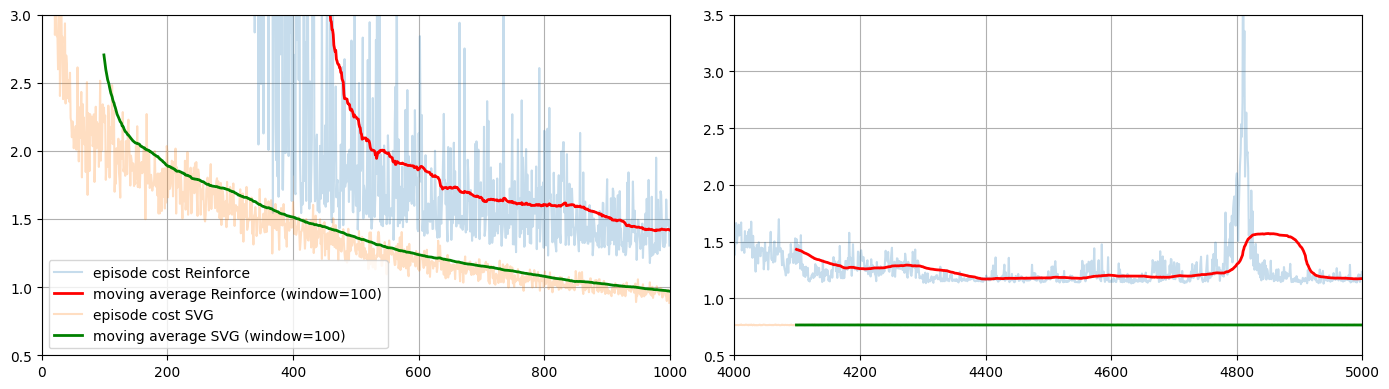

REINFORCE letzte 1000: min=1.126 max=4.747 mean=1.267
SVG       letzte 1000: min=0.762 max=0.772 mean=0.767


In [88]:
# Plot SVG vs Reinforce mit MLP
window = 100
n_first = 1000                    # Episoden 0..1999
n_last  = 1000                    # letzte 2000 Episoden

# Teilung in Anfangsbereich und Endbereich:
costs_first = costs[:n_first]
costs_last  = costs[-n_last:]
costs_first_pw = costs_pathwise[:n_first]
costs_last_pw  = costs_pathwise[-n_last:]

# Moving Average für beide Costs berechnen:
ma_first = np.convolve(costs_first, np.ones(window)/window, mode='valid')
ma_last  = np.convolve(costs_last,  np.ones(window)/window, mode='valid')
ma_first_pw = np.convolve(costs_first_pw, np.ones(window)/window, mode='valid')
ma_last_pw  = np.convolve(costs_last_pw,  np.ones(window)/window, mode='valid')

# x-Achse strukturieren:
ep_first = np.arange(n_first)
ep_last  = np.arange(num_episodes - n_last, num_episodes)

# Plot beginnen
#-------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Costs Reinforce
axes[0].plot(
    ep_first, costs_first, alpha=0.25, label='episode cost Reinforce')
# Mean Average Reinforce
axes[0].plot(np.arange(window - 1, n_first), ma_first, 'r-', lw=2,
             label=f'moving average Reinforce (window={window})')
# Costs SVG
axes[0].plot(
    ep_first, costs_first_pw, alpha=0.25, label='episode cost SVG')
# Mean Average SVG
axes[0].plot(np.arange(window - 1, n_first), ma_first_pw, 'g-', lw=2,
             label=f'moving average SVG (window={window})')
axes[0].legend(); axes[0].grid(True)

# Costs Reinforce
axes[1].plot(
    ep_last, costs_last, alpha=0.25, label='episode cost Reinforce')
# Costs SVG
axes[1].plot(
    ep_last, costs_last_pw, alpha=0.25, label='episode cost SVG')
# Mean Average Reinforce
axes[1].plot(ep_last[window - 1:], ma_last, 'r-', lw=2,
             label=f'moving average (window={window})')
# Mean Average SVG
axes[1].plot(ep_last[window - 1:], ma_last_pw, 'g-', lw=2,
             label=f'moving average (window={window})')
axes[1].grid(True)

axes[0].set_xlim((0.0,n_first)); axes[0].set_ylim((0.5,3.0))
axes[1].set_xlim((num_episodes-n_last,num_episodes)); axes[1].set_ylim((0.5,3.5))

plt.tight_layout()
plt.show()
print("REINFORCE letzte 1000: min=%.3f max=%.3f mean=%.3f" % (
    costs[-1000:].min(), costs[-1000:].max(), costs[-1000:].mean()))
print("SVG       letzte 1000: min=%.3f max=%.3f mean=%.3f" % (
    costs_pathwise[-1000:].min(), costs_pathwise[-1000:].max(), costs_pathwise[-1000:].mean()))

In [3]:
# CTRNN: Neural ODEs mit SVG für verschiedene Tiefen
import matplotlib.pyplot as plt
import numpy as np
from Policy_Gradient_NN import train_step, evaluate_policy, episode_cost ,train_step_pathwise
from NN import NeuralODE
from ControlProblem import OCP

np.random.seed(42)
env = OCP(N=100)
env.gradient_descent(max_iter=1000, tol=1e-6)   # Referenz

#policy = NeuralODE(layers=10, integration_steps= 10 ,input_dim=2, output_dim=1)
policy_pathwise2 = NeuralODE(
    layers=10,integration_steps= 2, input_dim=2, output_dim=1)
policy_pathwise4 = NeuralODE(
    layers=10,integration_steps= 4, input_dim=2, output_dim=1)
policy_pathwise10 = NeuralODE(
    layers=10,integration_steps= 10, input_dim=2, output_dim=1)
policy_pathwise20 = NeuralODE(
    layers=10,integration_steps= 20, input_dim=2, output_dim=1)

sigma = 1.0
alpha = 1e-3
num_episodes = 5000
costs = np.zeros(num_episodes)
costs_pathwise2 = np.zeros(num_episodes)
costs_pathwise4 = np.zeros(num_episodes)
costs_pathwise10 = np.zeros(num_episodes)
costs_pathwise20 = np.zeros(num_episodes)

for ep in range(num_episodes):
    # Update der Parameter: Ein Gradientenschritt
    #costs[ep] =  train_step(env, policy, sigma=sigma, alpha=alpha)
    costs_pathwise2[ep] =  train_step_pathwise(
        env, policy_pathwise2, sigma=sigma, alpha=alpha)
    costs_pathwise4[ep] =  train_step_pathwise(
        env, policy_pathwise4, sigma=sigma, alpha=alpha)
    costs_pathwise10[ep] =  train_step_pathwise(
        env, policy_pathwise10, sigma=sigma, alpha=alpha)
    costs_pathwise20[ep] =  train_step_pathwise(
        env, policy_pathwise20, sigma=sigma, alpha=alpha)
    sigma = max(0.1, sigma * 0.999)

N=2: deterministische Kosten = 0.791457
N=4: deterministische Kosten = 0.782956
N=10: deterministische Kosten = 0.770102
N=20: deterministische Kosten = 0.783625
Referenz: 0.756421


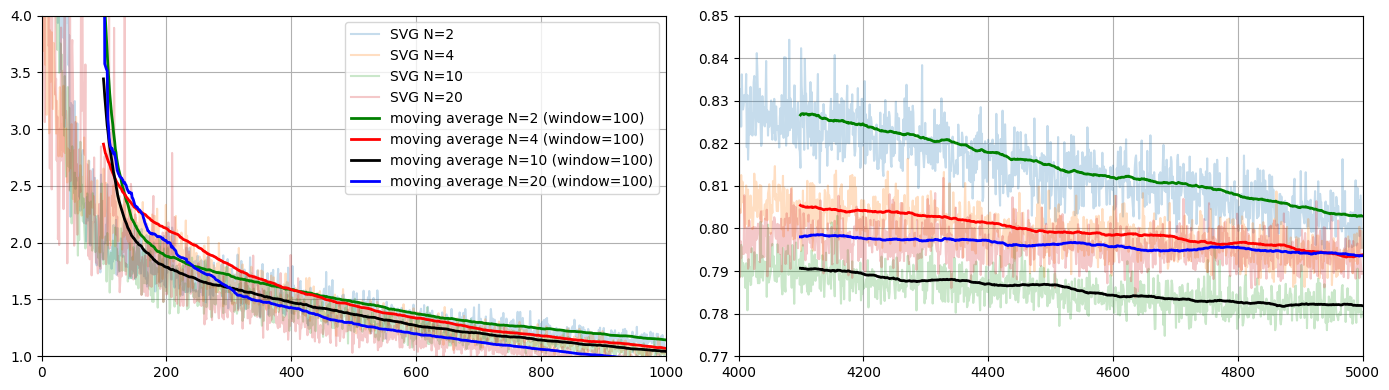

In [4]:
# Episodenkosten für verschiedene Tiefen der NeuralODE
window = 100
n_first = 1000                   # Episoden 0..1999
n_last  = 1000                   # letzte 2000 Episoden

# x-Achse strukturieren:
ep_first = np.arange(n_first)
ep_last  = np.arange(num_episodes - n_last, num_episodes)

# Plot beginnen
#-------------------------------------------------------------
plot_reinforce = False
plot_SVG = True

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

if plot_reinforce == True:
    costs_first = costs[:n_first]
    costs_last  = costs[-n_last:]
    ma_first = np.convolve(costs_first, np.ones(window)/window, mode='valid')
    ma_last  = np.convolve(costs_last,  np.ones(window)/window, mode='valid')
    # Costs Reinforce
    axes[0].plot(
        ep_first, costs_first, alpha=0.25, label='episode cost Reinforce')
    # Mean Average Reinforce
    axes[0].plot(np.arange(window - 1, n_first), ma_first, 'r-', lw=2,
                label=f'moving average Reinforce (window={window})')
    axes[1].plot(
        ep_last, costs_last, alpha=0.25, label='episode cost (stochastisch)')
    axes[1].plot(ep_last[window - 1:], ma_last, 'r-', lw=2,
             label=f'moving average (window={window})')
    axes[1].grid(True)
    
if plot_SVG == True:
    costs_first_pw2 = costs_pathwise2[:n_first]
    costs_first_pw4 = costs_pathwise4[:n_first]
    costs_first_pw10 = costs_pathwise10[:n_first]
    costs_first_pw20 = costs_pathwise20[:n_first]

    costs_last_pw2  = costs_pathwise2[-n_last:]
    costs_last_pw4  = costs_pathwise4[-n_last:]
    costs_last_pw10  = costs_pathwise10[-n_last:]
    costs_last_pw20  = costs_pathwise20[-n_last:]

    ma_first_pw2 = np.convolve(costs_first_pw2, np.ones(window)/window, mode='valid')
    ma_first_pw4 = np.convolve(costs_first_pw4, np.ones(window)/window, mode='valid')
    ma_first_pw10 = np.convolve(costs_first_pw10, np.ones(window)/window, mode='valid')
    ma_first_pw20 = np.convolve(costs_first_pw20, np.ones(window)/window, mode='valid')

    ma_last_pw2  = np.convolve(costs_last_pw2,  np.ones(window)/window, mode='valid')
    ma_last_pw4  = np.convolve(costs_last_pw4,  np.ones(window)/window, mode='valid')
    ma_last_pw10  = np.convolve(costs_last_pw10,  np.ones(window)/window, mode='valid')
    ma_last_pw20  = np.convolve(costs_last_pw20,  np.ones(window)/window, mode='valid')

    # Costs Pathwise
    axes[0].plot(
        ep_first, costs_first_pw2, alpha=0.25, label='SVG N=2')
    axes[0].plot(
        ep_first, costs_first_pw4, alpha=0.25, label='SVG N=4')
    axes[0].plot(
        ep_first, costs_first_pw10, alpha=0.25, label='SVG N=10')
    axes[0].plot(
        ep_first, costs_first_pw20, alpha=0.25, label='SVG N=20')
        
    # Mean Average Pathwise
    axes[0].plot(np.arange(window - 1, n_first), ma_first_pw2, 'g-', lw=2,
                label=f'moving average N=2 (window={window})')
    axes[0].plot(np.arange(window - 1, n_first), ma_first_pw4, 'r-', lw=2,
                label=f'moving average N=4 (window={window})')
    axes[0].plot(np.arange(window - 1, n_first), ma_first_pw10, 'k-', lw=2,
                label=f'moving average N=10 (window={window})')
    axes[0].plot(np.arange(window - 1, n_first), ma_first_pw20, 'b-', lw=2,
                label=f'moving average N=20 (window={window})')
    
    axes[0].legend(); axes[0].grid(True)


    axes[1].plot(
    ep_last, costs_last_pw2, alpha=0.25, label='episode cost (stochastisch)')
    axes[1].plot(
    ep_last, costs_last_pw4, alpha=0.25, label='episode cost (stochastisch)')
    axes[1].plot(
    ep_last, costs_last_pw10, alpha=0.25, label='episode cost (stochastisch)')
    axes[1].plot(
    ep_last, costs_last_pw20, alpha=0.25, label='episode cost (stochastisch)')

    axes[1].plot(ep_last[window - 1:], ma_last_pw2, 'g-', lw=2,
             label=f'moving average (window={window})')
    axes[1].plot(ep_last[window - 1:], ma_last_pw4, 'r-', lw=2,
             label=f'moving average (window={window})')
    axes[1].plot(ep_last[window - 1:], ma_last_pw10, 'k-', lw=2,
             label=f'moving average (window={window})')
    axes[1].plot(ep_last[window - 1:], ma_last_pw20, 'b-', lw=2,
             label=f'moving average (window={window})')
    
    axes[1].grid(True)
    
# Gemeinsame Grenzen für beide
axes[0].set_xlim((0.0,n_first)); axes[0].set_ylim((1.0,4.0))
axes[1].set_xlim((num_episodes - n_last, num_episodes)); axes[1].set_ylim((0.77,0.85))

for name, pol in [("N=2", policy_pathwise2), ("N=4", policy_pathwise4),
                  ("N=10", policy_pathwise10), ("N=20", policy_pathwise20)]:
    _, _, cost = evaluate_policy(env, pol)
    print(f"{name}: deterministische Kosten = {cost:.6f}")
print(f"Referenz: {env.J_numerical:.6f}")

plt.tight_layout()
plt.show()

u: mean=0.1635  max=0.3902 x: mean=0.0563  max=0.0805
u: mean=0.1399  max=0.3748 x: mean=0.0586  max=0.0796
u: mean=0.0997  max=0.2985 x: mean=0.0407  max=0.0553
u: mean=0.1450  max=0.3341 x: mean=0.0297  max=0.0540


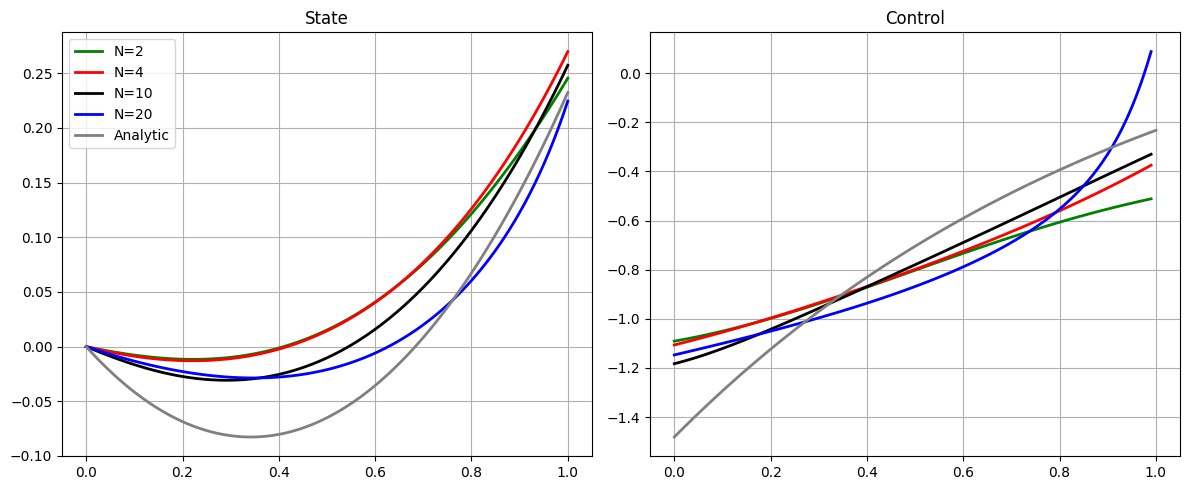

In [86]:
# Simulation der NeuralODE Policy am SVG 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))



for name, pol , color in [("N=2", policy_pathwise2, 'g'), ("N=4", policy_pathwise4, 'r'),
                  ("N=10", policy_pathwise10, 'k'), ("N=20", policy_pathwise20, 'b')]:
    traj, actions, _ = evaluate_policy(env, pol)
    # Fehler dokumentieren: 
    err_u = np.abs(actions - env.u[:-1])
    err_x = np.abs(traj - env.x)
    print(
        f"u: mean={err_u.mean():.4f}  max={err_u.max():.4f} x: mean={err_x.mean():.4f}  max={err_x.max():.4f}")

    axes[0].plot(env.t, traj, color = color, label=name, lw=2)
    axes[1].plot(env.t[:-1], actions,color =color, label=name, lw=2)
axes[0].set_title('State')
axes[0].plot(env.t, env.x,'grey', label='Analytic', lw=2)
axes[1].plot(env.t, env.u,'grey', label='Analytic', lw=2)
axes[1].set_title('Control')
axes[0].legend(); axes[0].grid(True)
axes[1].grid(True)
plt.tight_layout(); plt.show()

In [76]:
# Lernen des Gesamtfeldes auf beliebigen Startwerten x0
from NN import Neural_Network_One_Layer
import numpy as np
from ControlProblem import OCP
np.random.seed(42)
env = OCP(N=100)
env.gradient_descent(max_iter=1000, tol=1e-6)   # Referenz
Control = Neural_Network_One_Layer(n=20,input_dim=2, output_dim=1)
#Control_Reinforce = Neural_Network_One_Layer(n=20,input_dim=2, output_dim=1)
Episodes = 1000000
sigma = 1.0
alpha_reinforce = 1e-7
alpha_SVG = 1e-4
rewards = np.zeros(Episodes) #; rewards_Reinforce = np.zeros(Episodes)
for k in range(Episodes):
    x0 = 0.5 + 2 * np.random.randn()
    rewards[k] = train_step_pathwise(
        env,Control,sigma, alpha_SVG, initial_state= x0)
    #rewards_Reinforce[k] = train_step(
    #    env,Control_Reinforce,sigma, alpha_reinforce, initial_state= x0)
    sigma = max(0.1, sigma * 0.99998)
    

Kosten (gelernte Policy, deterministisch): 0.756758
Kosten (adjungierte Referenz):             0.756421
u:  mean|err| = 0.0159   max|err| = 0.0486   @ t = 0.990
x:  mean|err| = 0.0029   max|err| = 0.0073   @ t = 0.880


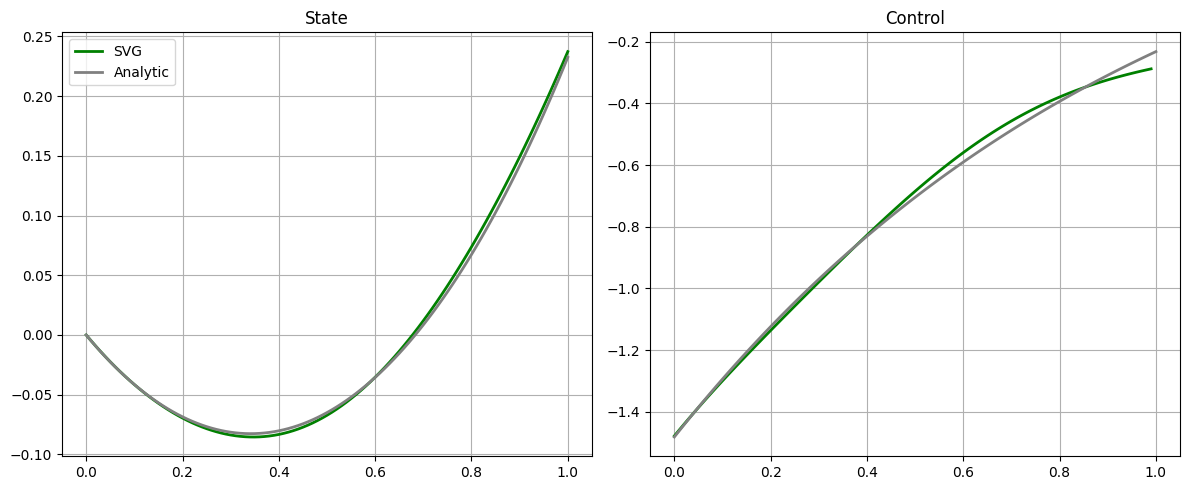

In [83]:
# Vergleich des allgemeinen Netzes gegen die Lösung von x0 = 0
x0 = 0.0
traj_learned, u_learned, cost_learned = evaluate_policy(
    env, Control, initial_state=x0)


print(f"Kosten (gelernte Policy, deterministisch): {cost_learned:.6f}")
print(f"Kosten (adjungierte Referenz):             {env.J_numerical:.6f}")
err_u = np.abs(u_learned - env.u[:-1])
print(f"u:  mean|err| = {err_u.mean():.4f}   max|err| = {err_u.max():.4f}   @ t = {env.t[np.argmax(err_u)]:.3f}")
err_x = np.abs(traj_learned - env.x)
print(f"x:  mean|err| = {err_x.mean():.4f}   max|err| = {err_x.max():.4f}   @ t = {env.t[np.argmax(err_x)]:.3f}")

# Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(env.t, traj_learned,      'g-',  label='SVG',   lw=2)
axes[0].plot(env.t, env.x,             'grey', label='Analytic', lw=2)
#axes[0].set_xlabel('t'); axes[0].set_ylabel('x(t)')
axes[0].set_title('State')
axes[0].legend(); axes[0].grid(True)

axes[1].plot(env.t[:-1], u_learned,        'g-',  label='SVG',   lw=2)
axes[1].plot(env.t,      env.u,            'grey', label='Analytic', lw=2)
#axes[1].set_xlabel('t'); axes[1].set_ylabel('u(t)')
axes[1].set_title('Control')
axes[1].grid(True)

plt.tight_layout(); plt.show()

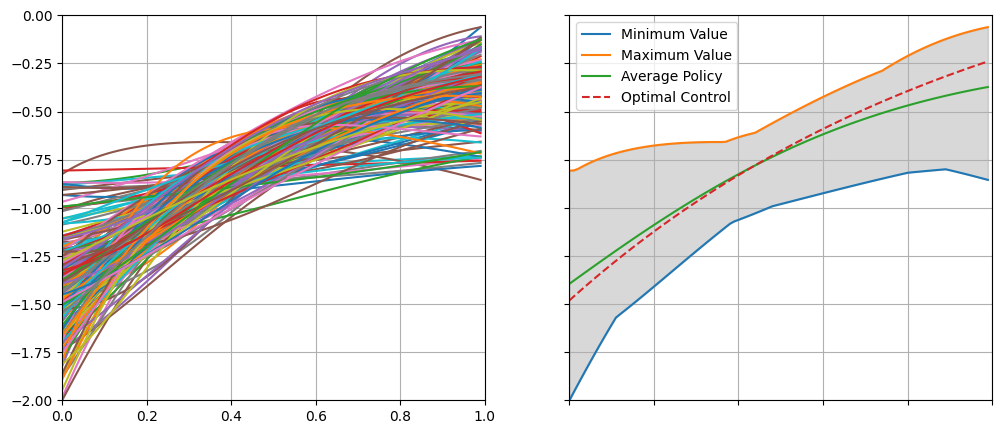

In [8]:
# Hier die Plots der empirischen Studie über 200 Trajektorien:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
Simulation_Control = np.loadtxt("Simulation_Control.csv", delimiter=",")
time_grid = np.linspace(0,1,101)
time_grid[0:-1].shape

for i in range(1,200):
    ax[0].plot(time_grid[0:-1], Simulation_Control[i])

min_values = np.zeros(Simulation_Control.shape[1])
for i in range(Simulation_Control.shape[1]):
    min_values[i] = np.min(Simulation_Control[:,i])

max_values = np.zeros(Simulation_Control.shape[1])
for i in range(Simulation_Control.shape[1]):
    max_values[i] = np.max(Simulation_Control[:,i])

avg_values = np.zeros(Simulation_Control.shape[1])
for i in range(Simulation_Control.shape[1]):
    avg_values[i] = np.mean(Simulation_Control[:,i])

ax[1].plot(time_grid[0:-1], min_values, label="Minimum Value")
ax[1].plot(time_grid[0:-1], max_values, label="Maximum Value")
ax[1].plot(time_grid[0:-1], avg_values, label="Average Policy")
ax[1].plot(time_grid[0:-1], env.u[:-1], label="Optimal Control", linestyle="--")
ax[1].fill_between(time_grid[0:-1], min_values, max_values, color="gray", alpha=0.3)

# Gemeinsame Grenzen für beide
xlim = (0.0, 1.0)
ylim = (-2.0, 0.0)
ax[0].set_xlim(xlim); ax[0].set_ylim(ylim)
ax[1].set_xlim(xlim); ax[1].set_ylim(ylim)

# Grid für BEIDE Plots aktivieren
ax[0].grid(True)
ax[1].grid(True)

ax[1].set_xticklabels([])
ax[1].set_yticklabels([])
plt.legend()
plt.show()

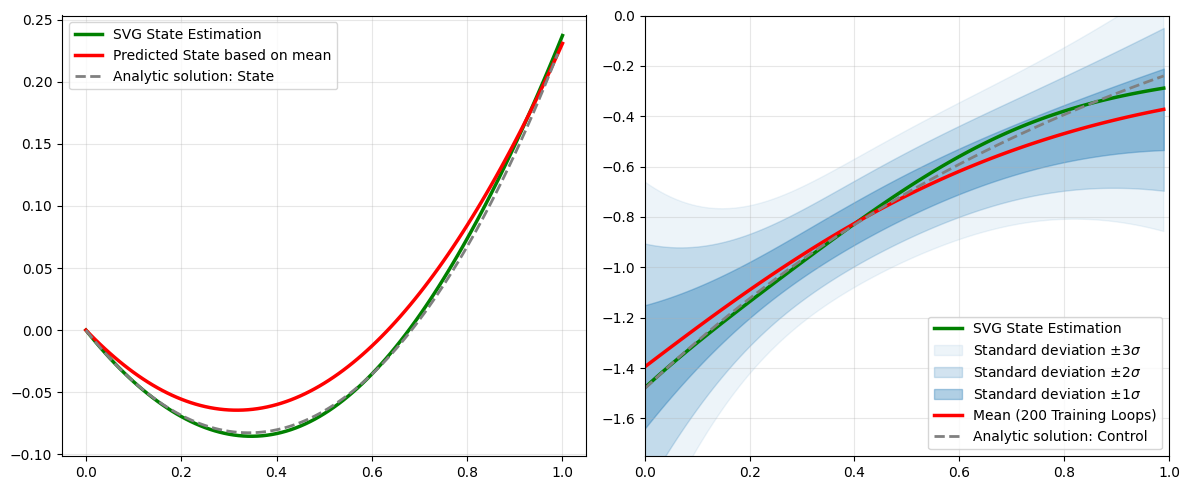

u: mean=0.0481  max=0.1328  @ t=0.99
x: mean=0.0151  max=0.0228  @ t=0.58
J(mean): 0.759995   J(ref): 0.756421   Δabs: 0.003574


In [91]:
import matplotlib.pyplot as plt
import numpy as np

Simulation_Control = np.loadtxt("Simulation_Control.csv", delimiter=",")
time_grid = np.linspace(0, 1, 101)
x_grid = np.zeros(101)

# Spalten: 0 = ?, 1..200 = Trajektorien? Prüfe die Form
# Annahme: Simulation_Control.shape = (200, 100) oder (200, 101)
# Filtere NaN/Inf, falls vorhanden
trajs = Simulation_Control[0:200]          # 199 Trajektorien (erste Zeile = Header?)
t = time_grid[:trajs.shape[1]]

mean_u = trajs.mean(axis=0)
std_u  = trajs.std(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1) Vergleich mit SVG auf dem Vektorfeld
ax[0].plot(time_grid, traj_learned, color='g', lw=2.5, label='SVG State Estimation')
ax[1].plot(time_grid[:-1], u_learned, color='g', lw=2.5, label='SVG State Estimation')

# Dynamik des OCP x'=x+u+1
for k in range(100):
    x_grid[k+1] = x_grid[k]+(1/100)*(x_grid[k]+mean_u[k]+1)

# 2) ±1σ-Band
ax[1].fill_between(t, mean_u - 3*std_u, mean_u + 3*std_u,
                color='tab:blue', alpha=0.08, label=r'Standard deviation $\pm 3\sigma$')
ax[1].fill_between(t, mean_u - 2*std_u, mean_u + 2*std_u,
                color='tab:blue', alpha=0.2, label=r'Standard deviation $\pm 2\sigma$')
ax[1].fill_between(t, mean_u - std_u, mean_u + std_u,
                color='tab:blue', alpha=0.35, label=r'Standard deviation $\pm 1\sigma$')


# 3) Mittelwert prominent
ax[1].plot(t, mean_u, color='red', lw=2.5, label='Mean (200 Training Loops)')
ax[0].plot(time_grid, x_grid, color='red', lw=2.5, label='Predicted State based on mean')

# 4) Analytische Lösung
ax[1].plot(env.t[:-1], env.u[:-1], color='grey', lw=2, linestyle='--',
        label='Analytic solution: Control')
ax[0].plot(env.t[:-1], env.x[:-1], color='grey', lw=2, linestyle='--',
        label='Analytic solution: State')

ax[1].set_xlim(0, 1)
ax[1].set_ylim(-1.75, 0.0)
ax[0].grid(True, alpha=0.3);ax[1].grid(True, alpha=0.3)
ax[0].legend(loc='best'); ax[1].legend(loc='best')
plt.tight_layout()
plt.show()

err_u = np.abs(mean_u - env.u[:-1])
err_x = np.abs(x_grid - env.x)
print(f"u: mean={err_u.mean():.4f}  max={err_u.max():.4f}  @ t={t[np.argmax(err_u)]:.2f}")
print(f"x: mean={err_x.mean():.4f}  max={err_x.max():.4f}  @ t={time_grid[np.argmax(err_x)]:.2f}")
J_mean = env.h * np.sum(x_grid[:-1] + mean_u**2) + x_grid[-1]**2
print(f"J(mean): {J_mean:.6f}   J(ref): {env.J_numerical:.6f}   Δabs: {abs(J_mean-env.J_numerical):.6f}")